In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load the heart disease dataset

file_path = "heart_disease_combined_raw(3).csv"

df = pd.read_csv('C:\\Users\\User\\Downloads\\heart+disease\\heart_disease_combined_raw(3).csv'
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
# Display the first five records

print("First five records of the dataset:")
display(df.head())

First five records of the dataset:


,source,id,ccf,age,sex,painloc,painexer,relrest,pncaden,cp,...,rcaprox,rcadist,lvx1,lvx2,lvx3,lvx4,lvf,cathef,junk,name
0,Cleveland,1,0,63,1,-9,-9,-9,-9,1,...,1,1,1,1,1,1,1,-9.0,-9.0,name
1,Cleveland,2,0,67,1,-9,-9,-9,-9,4,...,1,1,1,1,1,1,1,-9.0,-9.0,name
2,Cleveland,3,0,67,1,-9,-9,-9,-9,4,...,2,2,1,1,1,7,3,-9.0,-9.0,name
3,Cleveland,4,0,37,1,-9,-9,-9,-9,3,...,1,1,1,1,1,1,1,-9.0,-9.0,name
4,Cleveland,6,0,41,0,-9,-9,-9,-9,2,...,1,1,1,1,1,1,1,-9.0,-9.0,name


In [5]:
# Determine the number of records and features

rows, columns = df.shape

print("Number of records:", rows)
print("Number of columns:", columns)
print("Dataset shape:", df.shape)

Number of records: 900
Number of columns: 77
Dataset shape: (900, 77)


In [6]:
# Display all column names

print("Column names:")
print()

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Column names:

1. source
2. id
3. ccf
4. age
5. sex
6. painloc
7. painexer
8. relrest
9. pncaden
10. cp
11. trestbps
12. htn
13. chol
14. smoke
15. cigs
16. years
17. fbs
18. dm
19. famhist
20. restecg
21. ekgmo
22. ekgday
23. ekgyr
24. dig
25. prop
26. nitr
27. pro
28. diuretic
29. proto
30. thaldur
31. thaltime
32. met
33. thalach
34. thalrest
35. tpeakbps
36. tpeakbpd
37. dummy
38. trestbpd
39. exang
40. xhypo
41. oldpeak
42. slope
43. rldv5
44. rldv5e
45. ca
46. restckm
47. exerckm
48. restef
49. restwm
50. exeref
51. exerwm
52. thal
53. thalsev
54. thalpul
55. earlobe
56. cmo
57. cday
58. cyr
59. num
60. lmt
61. ladprox
62. laddist
63. diag
64. cxmain
65. ramus
66. om1
67. om2
68. rcaprox
69. rcadist
70. lvx1
71. lvx2
72. lvx3
73. lvx4
74. lvf
75. cathef
76. junk
77. name


In [7]:
# Display data types of all features

print("Feature Data Types:")
print()

display(
    pd.DataFrame({
        "Feature": df.columns,
        "Data Type": df.dtypes.astype(str).values
    })
)

Feature Data Types:



,Feature,Data Type
0,source,str
1,id,int64
2,ccf,int64
3,age,int64
4,sex,int64
...,...,...
72,lvx4,int64
73,lvf,int64
74,cathef,float64
75,junk,float64


In [8]:
# Display general information about the dataset

print("Dataset Information:")
print()

df.info()

Dataset Information:

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 77 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   source    900 non-null    str    
 1   id        900 non-null    int64  
 2   ccf       900 non-null    int64  
 3   age       900 non-null    int64  
 4   sex       900 non-null    int64  
 5   painloc   900 non-null    int64  
 6   painexer  900 non-null    int64  
 7   relrest   900 non-null    int64  
 8   pncaden   900 non-null    int64  
 9   cp        900 non-null    int64  
 10  trestbps  900 non-null    int64  
 11  htn       900 non-null    int64  
 12  chol      900 non-null    int64  
 13  smoke     900 non-null    int64  
 14  cigs      900 non-null    int64  
 15  years     900 non-null    str    
 16  fbs       900 non-null    int64  
 17  dm        900 non-null    int64  
 18  famhist   900 non-null    int64  
 19  restecg   900 non-null    int64  
 20  ekgmo     900 non-nul

In [9]:
# Inspect the original target variable

print("Original target variable: num")
print()

print("Unique target values:")
print(sorted(df["num"].dropna().unique()))

print("\nFrequency of each target value:")
print(df["num"].value_counts().sort_index())

Original target variable: num

Unique target values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(80)]

Frequency of each target value:
num
0     404
1     191
2     130
3     132
4      42
80      1
Name: count, dtype: int64


In [10]:
# Create binary target variable

df_model = df.copy()

df_model["target"] = (df_model["num"] > 0).astype(int)

print("Binary target variable created successfully.")

print("\nTarget mapping:")
print("0 → No Heart Disease")
print("1 → Heart Disease Present")

Binary target variable created successfully.

Target mapping:
0 → No Heart Disease
1 → Heart Disease Present


In [11]:
# Display binary target distribution

target_counts = df_model["target"].value_counts().sort_index()

print("Binary Target Distribution:")
print()

print("No Heart Disease (0):", target_counts.get(0, 0))
print("Heart Disease (1):", target_counts.get(1, 0))

Binary Target Distribution:

No Heart Disease (0): 404
Heart Disease (1): 496


In [12]:
# Calculate target percentages

target_percentage = (
    df_model["target"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Target Class Distribution:")
print()

for class_value, percentage in target_percentage.items():

    if class_value == 0:
        label = "No Heart Disease"
    else:
        label = "Heart Disease"

    print(
        f"{class_value} - {label}: "
        f"{percentage:.2f}%"
    )

Target Class Distribution:

0 - No Heart Disease: 44.89%
1 - Heart Disease: 55.11%


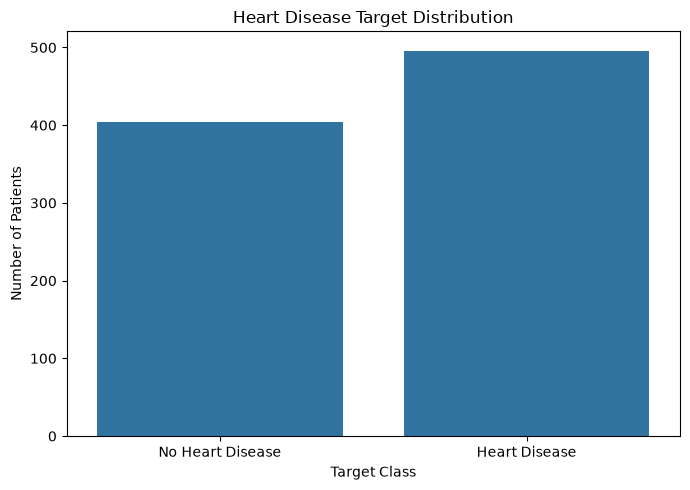

In [13]:
# Visualize binary target distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    x=df_model["target"]
)

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")

plt.xticks(
    [0, 1],
    ["No Heart Disease", "Heart Disease"]
)

plt.tight_layout()
plt.show()

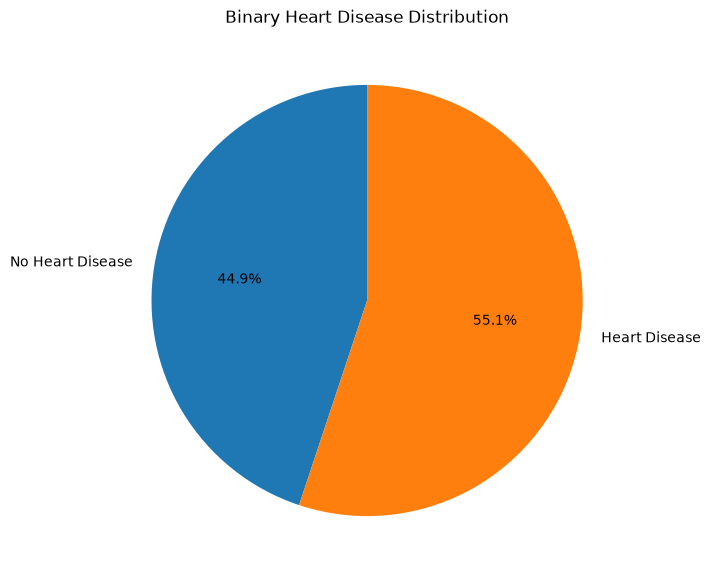

In [14]:
# Pie chart of target distribution

labels = ["No Heart Disease", "Heart Disease"]

values = [
    target_counts.get(0, 0),
    target_counts.get(1, 0)
]

plt.figure(figsize=(7, 7))

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Binary Heart Disease Distribution")

plt.show()

In [15]:
# Check the prepared dataset

print("Original dataset shape:", df.shape)
print("Prepared dataset shape:", df_model.shape)

print("\nTarget column added:", "target" in df_model.columns)

print("\nFinal target values:")
print(sorted(df_model["target"].unique()))

Original dataset shape: (900, 77)
Prepared dataset shape: (900, 78)

Target column added: True

Final target values:
[np.int64(0), np.int64(1)]
